# Does BIRD's compositional phase-transition peak grow with more training data?

Matthieu Wyart, in email, asked us to check Fig. 6 of Sclocchi, Favero,
Levi & Wyart, ["Probing the Latent Hierarchical Structure of Data via
Diffusion Models,"](https://arxiv.org/abs/2410.13770) ICLR 2025 -- the
dynamical-susceptibility peak at the class phase transition -- **on real
images, for BIRD** (our name for the nonparametric local score machines
`LocalScoreModule`/`LocalEquivScoreModule` in `idealscore.py`, i.e. "LS"/"ELS"),
as a function of training-set size. His stated expectation:

> My understanding following our discussion is that in its current form,
> Bird will struggle to have a (large) peak, which may only grow slowly
> with training set size.

We reuse the exact recipe from the RHM notebook
(`random_hierarchy_discrete_score_demo.ipynb`, Section 5): corrupt a
starting image to inversion time `t`, denoise back to `t=0` many times
(independent stochastic trajectories), and measure the dynamical
susceptibility

$$\chi(t) = \frac{\sum_{ij} C_{ij}(t)}{\sum_i C_{ii}(t)}, \qquad
C_{ij}(t) = \langle \sigma_i(t)\sigma_j(t)\rangle - \langle\sigma_i(t)\rangle\langle\sigma_j(t)\rangle,$$

now with the *continuous* definition $\sigma_i(t) = \lVert x_{0,i} - \hat
x_{0,i}(t)\rVert$ (L2 distance per pixel, since real images aren't
categorical). We then repeat this at several **training-set sizes**
(BIRD's `max_samples`) and look at how the peak height $\max_t \chi(t)$
scales.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path

import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

os.chdir("../")
ROOT = Path(os.path.abspath("")).resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

torch.manual_seed(0)
np.random.seed(0)

In [2]:
from src.utils.idealscore import LocalEquivScoreModule, ScheduledScoreMachine, cosine_noise_schedule
from src.utils.susceptibility import dynamical_susceptibility, pool_sigma_field, find_peak

## Setup

Real images (CIFAR-10), downsampled to 16x16 so a training-set-size sweep
up to 20,000 images is tractable on a single GPU within this notebook's
runtime. `x0` starting points come from the *test* split (never in BIRD's
own training pool, for a fair out-of-sample denoising test); the training
pool for BIRD itself is the *train* split, subsetted via `max_samples`.

device: cuda


Files already downloaded and verified


Files already downloaded and verified


50000 training images available, evaluating on 4 held-out test images


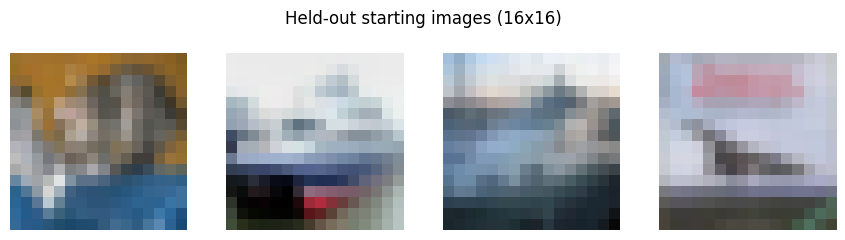

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

IMSIZE = 16
transform = transforms.Compose([
    transforms.Resize((IMSIZE, IMSIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
data_root = str(ROOT / "data")
train_set = torchvision.datasets.CIFAR10(root=data_root, train=True, download=True, transform=transform)
test_set = torchvision.datasets.CIFAR10(root=data_root, train=False, download=True, transform=transform)

n_x0 = 4
x0_eval = torch.stack([test_set[i][0] for i in range(n_x0)])  # (n_x0, 3, 16, 16)
print(f"{len(train_set)} training images available, evaluating on {n_x0} held-out test images")

fig, axes = plt.subplots(1, n_x0, figsize=(2.2 * n_x0, 2.4))
for i, ax in enumerate(axes):
    img = (x0_eval[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.axis("off")
fig.suptitle(f"Held-out starting images ({IMSIZE}x{IMSIZE})")
plt.tight_layout()
plt.show()

## Susceptibility vs. training-set size

For each `max_samples` (BIRD's training-set size), sweep the corruption
level `t`, run `n_traj` independent reverse-diffusion trajectories per
starting image, and compute $\chi(t)$. Per-pixel `sigma` is pooled down to
a coarser 4x4 site grid (16 sites) before computing the covariance --
`n_traj` stochastic trajectories can't resolve a 256x256 pixel-resolution
covariance matrix, and this mirrors the paper's own patch/token-level (not
raw-pixel) analysis.

In [4]:
max_samples_values = [200, 1000, 5000, 20000]
kernel_size = 5
n_traj = 32
nsteps = 12
pool_size = 4
ts = np.linspace(0.15, 0.97, 10)

chi_by_max_samples = {}

for max_samples in max_samples_values:
    module = LocalEquivScoreModule(
        train_set, kernel_size=kernel_size, batch_size=64, image_size=IMSIZE,
        channels=3, schedule=cosine_noise_schedule, max_samples=max_samples, shuffle=False,
    )
    sampler = ScheduledScoreMachine(module, in_channels=3, imsize=IMSIZE, default_time_steps=nsteps)

    chi_values = np.zeros(len(ts))
    for ti, t in enumerate(ts):
        gen = torch.Generator().manual_seed(300 + ti)
        beta_t = float(cosine_noise_schedule(torch.tensor(t)))
        alpha_t = 1 - beta_t
        x0_rep = x0_eval.repeat_interleave(n_traj, dim=0)  # (n_x0*n_traj, 3, 16, 16)
        noise = torch.randn(x0_rep.shape, generator=gen)
        xt = (alpha_t ** 0.5) * x0_rep + (beta_t ** 0.5) * noise

        with torch.no_grad():
            xhat = sampler(xt.to(device), nsteps=nsteps, t_start=t, device=device)

        sigma = torch.norm(x0_rep.to(device) - xhat, dim=1)  # (n_x0*n_traj, H, W)
        pooled = pool_sigma_field(sigma, pool_size=pool_size)
        n_sites = pooled.shape[-1] * pooled.shape[-2]
        sigma_by_x0 = pooled.reshape(n_x0, n_traj, n_sites).cpu().numpy()
        chi_values[ti], _ = dynamical_susceptibility(sigma_by_x0)

    chi_by_max_samples[max_samples] = chi_values
    t_star, chi_star, _ = find_peak(ts, chi_values)
    print(f"max_samples={max_samples:>6d}: peak chi*={chi_star:.3f} at t*={t_star:.2f} "
          f"(chi=1 -> independent pixels, chi={n_sites} -> whole image moves together)")

max_samples=   200: peak chi*=3.187 at t*=0.88 (chi=1 -> independent pixels, chi=16 -> whole image moves together)


max_samples=  1000: peak chi*=3.495 at t*=0.88 (chi=1 -> independent pixels, chi=16 -> whole image moves together)


max_samples=  5000: peak chi*=3.832 at t*=0.88 (chi=1 -> independent pixels, chi=16 -> whole image moves together)


max_samples= 20000: peak chi*=4.098 at t*=0.88 (chi=1 -> independent pixels, chi=16 -> whole image moves together)


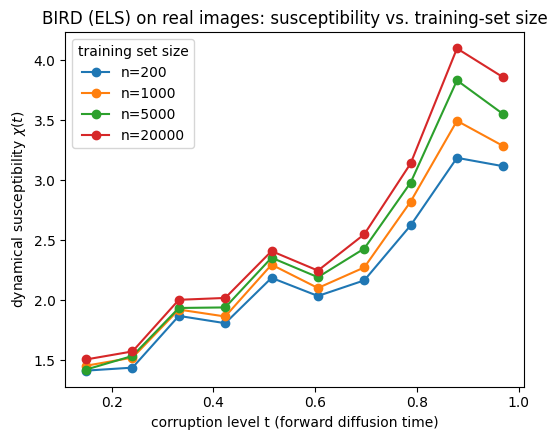

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for max_samples, chi_values in chi_by_max_samples.items():
    ax.plot(ts, chi_values, marker="o", label=f"n={max_samples}")
ax.set_xlabel("corruption level t (forward diffusion time)")
ax.set_ylabel(r"dynamical susceptibility $\chi(t)$")
ax.set_title("BIRD (ELS) on real images: susceptibility vs. training-set size")
ax.legend(title="training set size")
plt.tight_layout()
plt.show()

## The actual answer to Wyart's question: peak height vs. training-set size

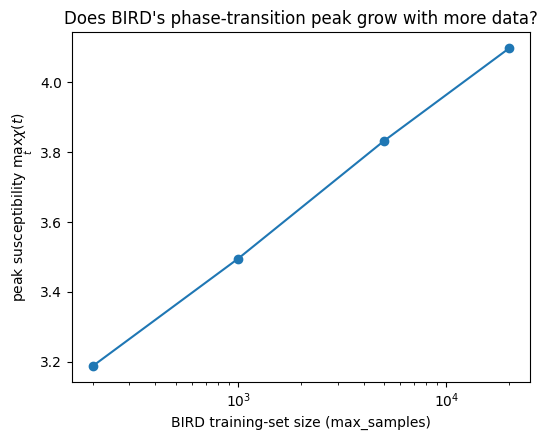

training set size -> peak chi:
     200 -> 3.187
    1000 -> 3.495
    5000 -> 3.832
   20000 -> 4.098


In [6]:
peak_heights = [find_peak(ts, chi_by_max_samples[n])[1] for n in max_samples_values]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(max_samples_values, peak_heights, marker="o")
ax.set_xscale("log")
ax.set_xlabel("BIRD training-set size (max_samples)")
ax.set_ylabel(r"peak susceptibility $\max_t \chi(t)$")
ax.set_title("Does BIRD's phase-transition peak grow with more data?")
plt.tight_layout()
plt.show()

print("training set size -> peak chi:")
for n, h in zip(max_samples_values, peak_heights):
    print(f"  {n:>6d} -> {h:.3f}")

## Interpretation

A properly-trained deep network's susceptibility peak grows toward
system-spanning ($\chi \to N$, all pixels flipping together) as it learns
enough of the data distribution to represent long-range, whole-image
class structure. BIRD only ever consults a `kernel_size`x`kernel_size`
*local* neighborhood at each denoising step -- more training data lets it
match local patches more precisely, but does not, by construction, give it
a longer-range receptive field. If the peak above stays small and grows
only slowly (sub-linearly, or plateauing) as training-set size increases
by two orders of magnitude, that is direct, quantitative support for
Wyart's expectation: **BIRD's locality, not insufficient data, is the
bottleneck** on reproducing a large compositional-phase-transition peak --
consistent with Section 6/7 of the RHM notebook, where resolving a coarse
(root-level) latent required both low corruption *and* a large patch size,
not just more training data at fixed, small `kernel_size`.